<a href="https://colab.research.google.com/github/Nyangweso1/cybershujaa-data-ai-track/blob/main/Prudence_Nyangweso_Week7_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Regression: Home Price Prediction
**Data & AI Programme: Week 7 Practical Assignment**
Prudence Moraa Nyangweso (CS-DAI04-26004)

Project structure: **1. Explore Dataset → 2. Build Model → 3. Test Model**
Target: `price`. Features: area, bedrooms, bathrooms, age, location_score, garage_type, condition.

# 1. Explore Dataset
### Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format      # readable numbers (no scientific notation)

### Upload and load the dataset
Run the cell, click **Choose files** and select `homeprices.csv`.

In [ ]:
from google.colab import files
uploaded = files.upload()
filename = list(uploaded.keys())[0]          # works even if Colab renames the file

# keep_default_na=False so the text "None" (= no garage) is NOT turned into a missing value
df = pd.read_csv(filename, keep_default_na=False, na_values=[""])
df.head()

Saving homeprices.csv to homeprices (3).csv


,area,bedrooms,bathrooms,age,location_score,garage_type,condition,price
0,3974,4,1.00,34.00,6.70,Attached,Excellent,809013
1,4307,1,2.00,79.00,2.70,Detached,Fair,669331
2,1660,5,NaN,60.00,1.60,Attached,Good,333718
3,2094,5,2.00,40.00,4.60,Attached,Poor,488932
4,1930,2,2.00,99.00,1.50,Attached,Fair,249520


### Explore the structure

In [ ]:
print("Shape:", df.shape)
df.info()

Shape: (100, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area            100 non-null    int64  
 1   bedrooms        100 non-null    int64  
 2   bathrooms       95 non-null     float64
 3   age             92 non-null     float64
 4   location_score  100 non-null    float64
 5   garage_type     100 non-null    object 
 6   condition       100 non-null    object 
 7   price           100 non-null    object 
dtypes: float64(3), int64(2), object(3)
memory usage: 6.4+ KB


In [ ]:
df.describe()

,area,bedrooms,bathrooms,age,location_score
count,100.00,100.00,95.00,92.00,100.00
mean,"2,866.51",3.19,2.04,50.22,5.29
std,"1,400.07",2.29,0.91,30.39,2.72
min,821.00,1.00,1.00,1.00,1.10
25%,"1,929.75",1.75,1.00,26.75,2.70
50%,"2,864.50",3.00,2.00,47.00,5.05
75%,"3,707.75",4.00,3.00,67.25,7.45
max,"12,000.00",20.00,6.00,150.00,9.80


In [ ]:
print("Missing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nGarage types:")
print(df["garage_type"].value_counts())
print("\nCondition:")
print(df["condition"].value_counts())

Missing values:
area              0
bedrooms          0
bathrooms         5
age               8
location_score    0
garage_type       0
condition         0
price             0
dtype: int64

Duplicate rows: 0

Garage types:
garage_type
Attached    50
Detached    38
None         8
Street       3
detached     1
Name: count, dtype: int64

Condition:
condition
Good         47
Fair         21
Excellent    18
Poor         14
Name: count, dtype: int64


**Problems found:**
1. `price` is text (one value is written as `"$550,000"`).
2. `garage_type` has `detached` and `Detached` (inconsistent spelling).
3. `bathrooms` and `age` have missing values.
4. Some rows look wrong (see the outlier check below).

### Clean the data

In [ ]:
# 1. price: remove $ and , then convert to number
df["price"] = pd.to_numeric(df["price"].astype(str).str.replace("$", "", regex=False).str.replace(",", "", regex=False))

# 2. make text consistent
df["garage_type"] = df["garage_type"].str.strip().str.title()
df["condition"] = df["condition"].str.strip().str.title()

# 3. condition is ordered, so use a number scale
df["condition"] = df["condition"].map({"Poor": 1, "Fair": 2, "Good": 3, "Excellent": 4})

print(df.dtypes)
print(df["garage_type"].unique())

area                int64
bedrooms            int64
bathrooms         float64
age               float64
location_score    float64
garage_type        object
condition           int64
price               int64
dtype: object
['Attached' 'Detached' 'None' 'Street']


### Check outliers
A boxplot shows extreme values; then we list the rows that break common sense.

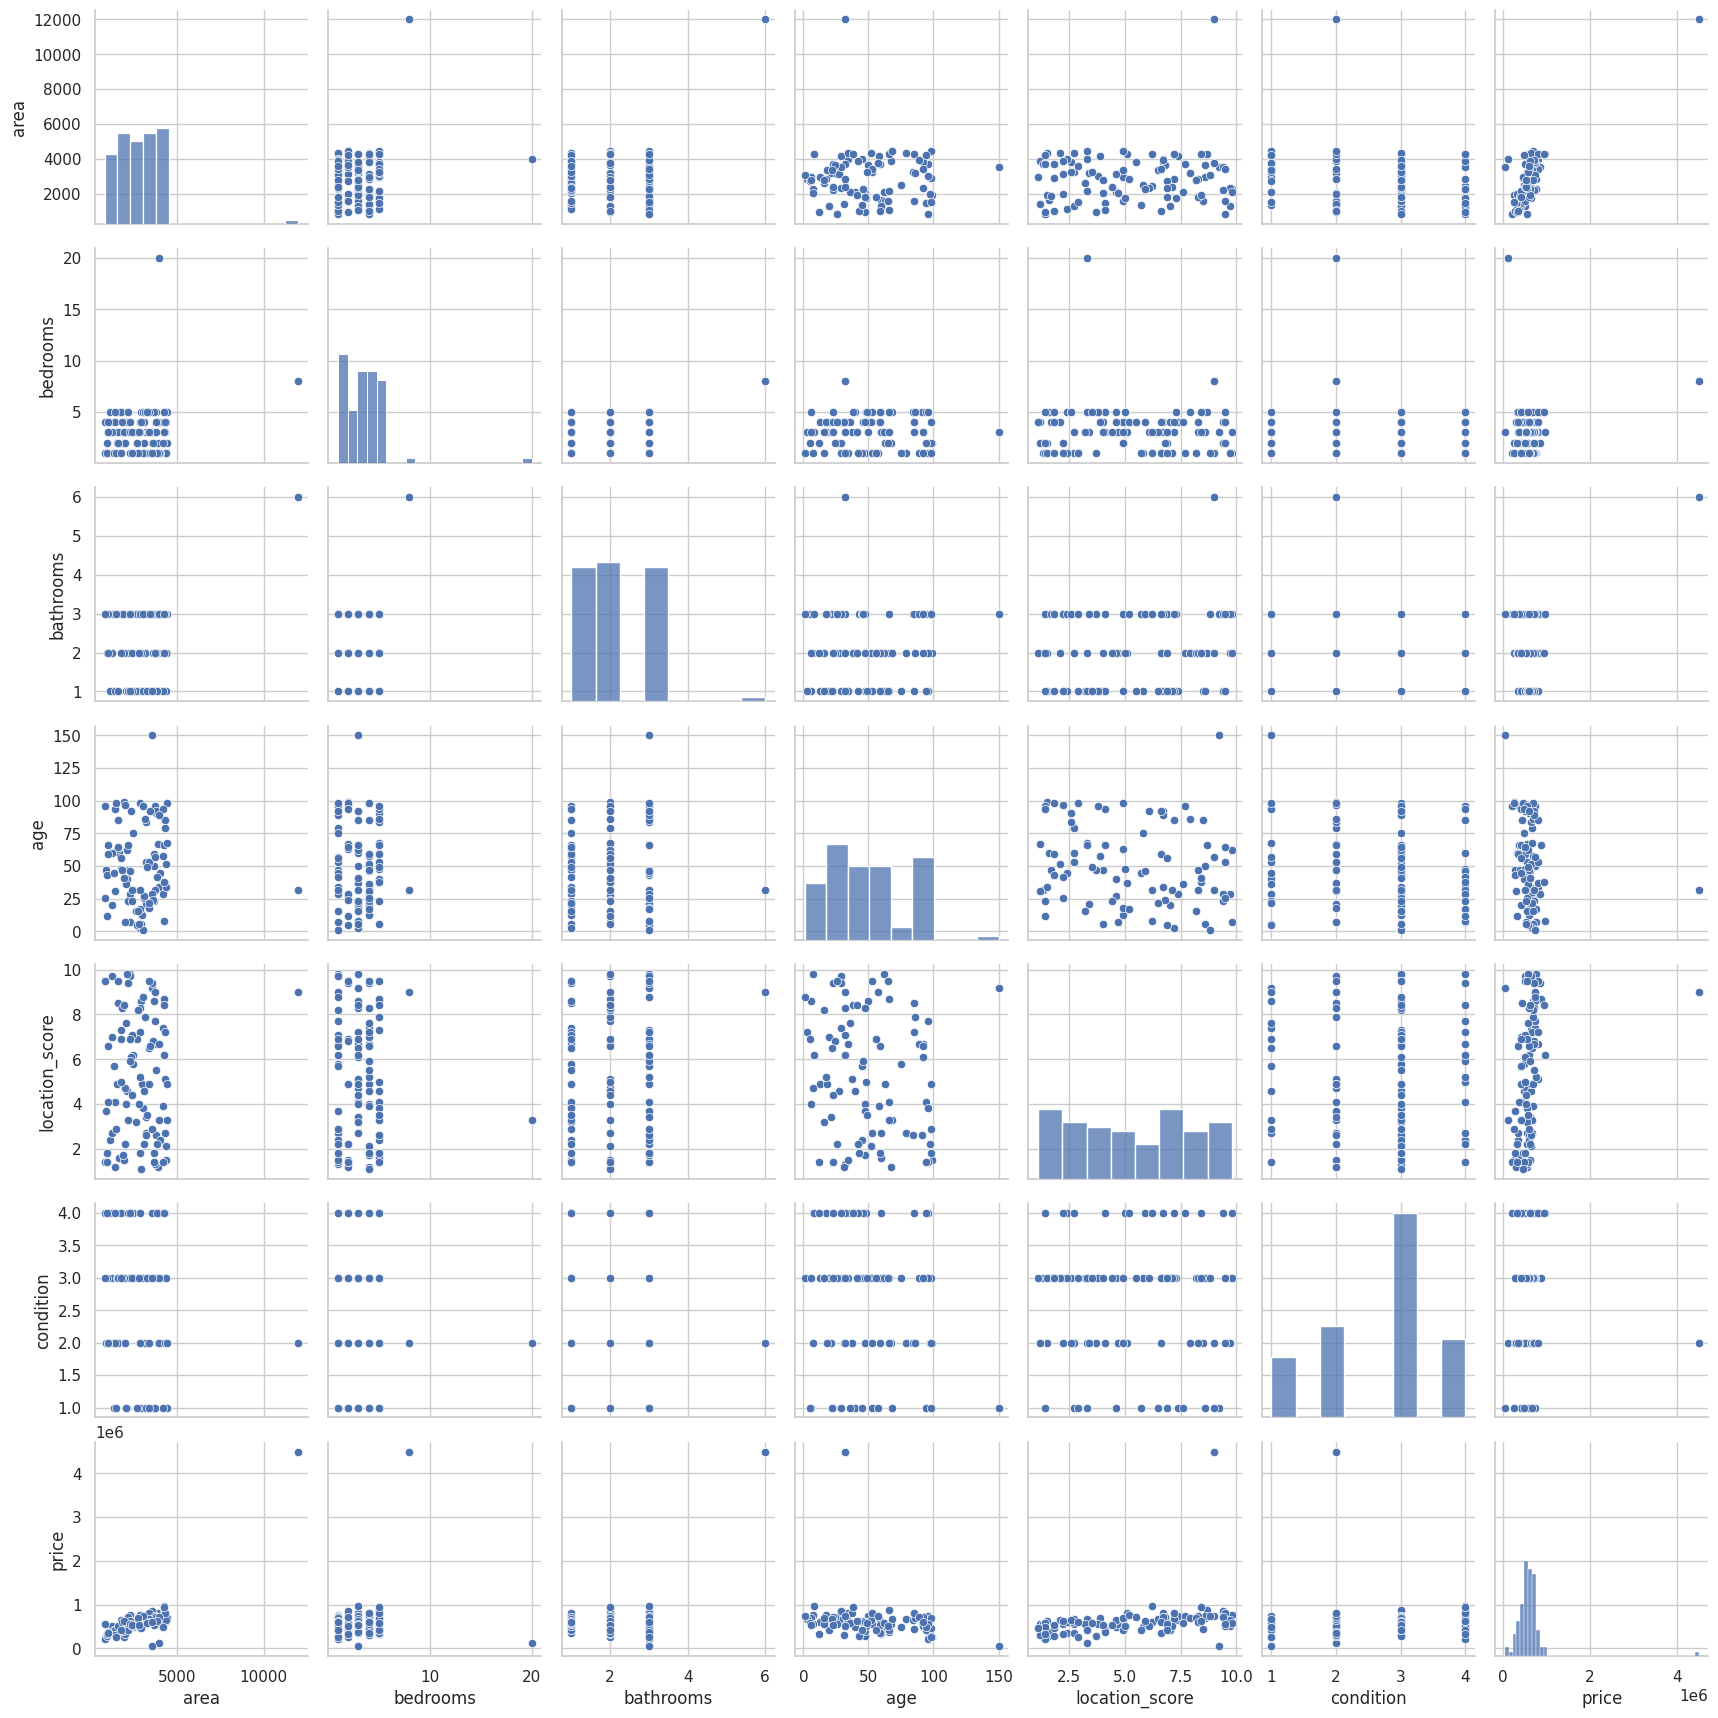

In [ ]:
sns.pairplot(df)
plt.show()

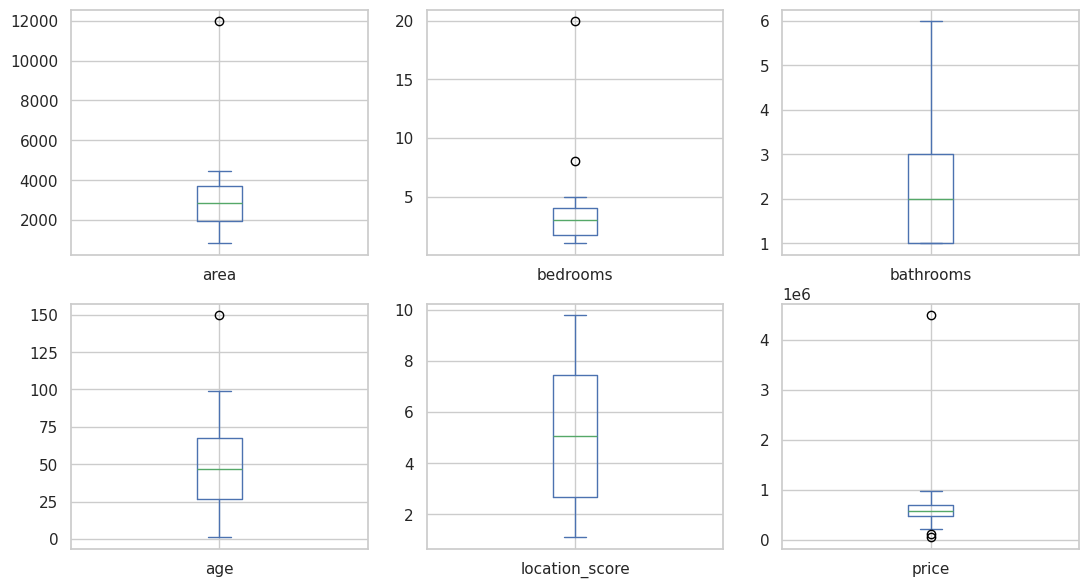

In [ ]:
cols = ["area", "bedrooms", "bathrooms", "age", "location_score", "price"]
df[cols].plot(kind="box", subplots=True, layout=(2, 3), figsize=(13, 7))
plt.show()

In [ ]:
# rows that are impossible or very unusual: more than 10 bedrooms, older than 120 years, area above 8000
bad = df[(df["bedrooms"] > 10) | (df["age"] > 120) | (df["area"] > 8000)]
bad

,area,bedrooms,bathrooms,age,location_score,garage_type,condition,price
5,12000,8,6.00,32.00,9.00,Detached,2,4500000
15,3971,20,NaN,NaN,3.30,Detached,2,120000
42,3547,3,3.00,150.00,9.20,Attached,1,45000


These 3 rows do not follow the pattern of the rest (for example 20 bedrooms priced at 120,000, or a 150-year-old house priced at 45,000). They are probably data-entry errors and would pull the regression line off, so they are removed.

In [ ]:
df = df.drop(bad.index).reset_index(drop=True)
print("Rows left:", len(df))

Rows left: 97


### Visualise the data

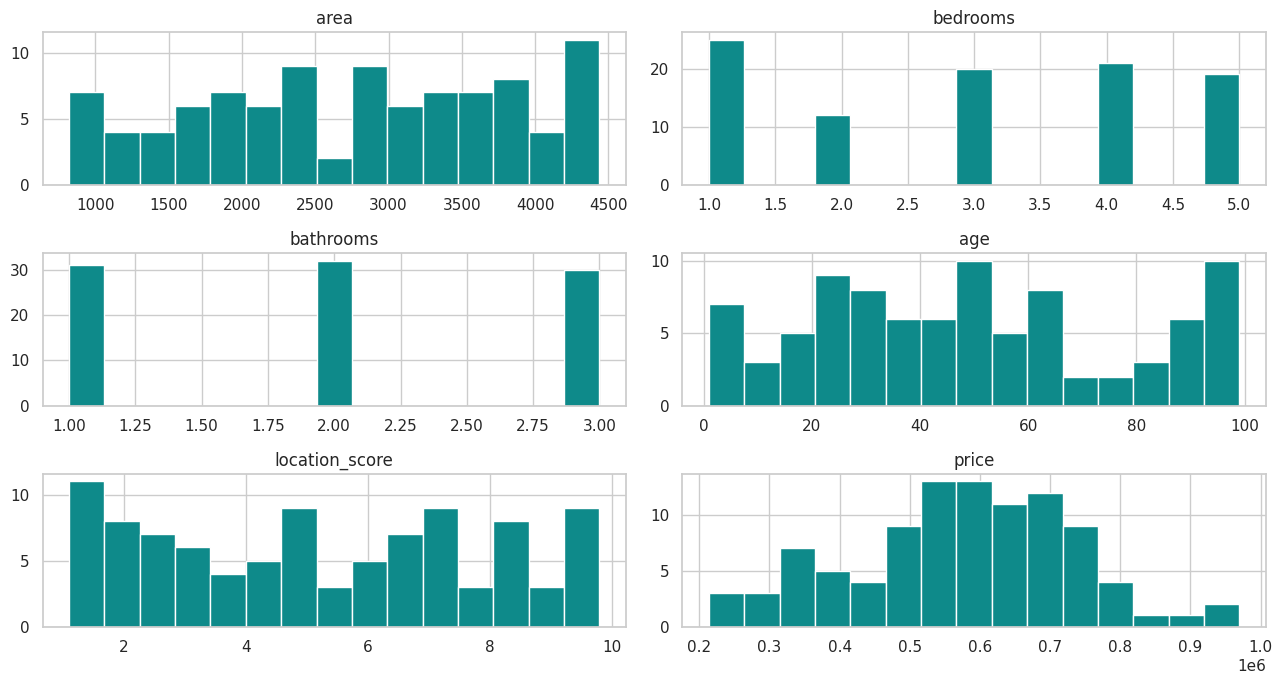

In [ ]:
df[cols].hist(bins=15, figsize=(13, 7), color="#0E8A8A")
plt.tight_layout()
plt.show()

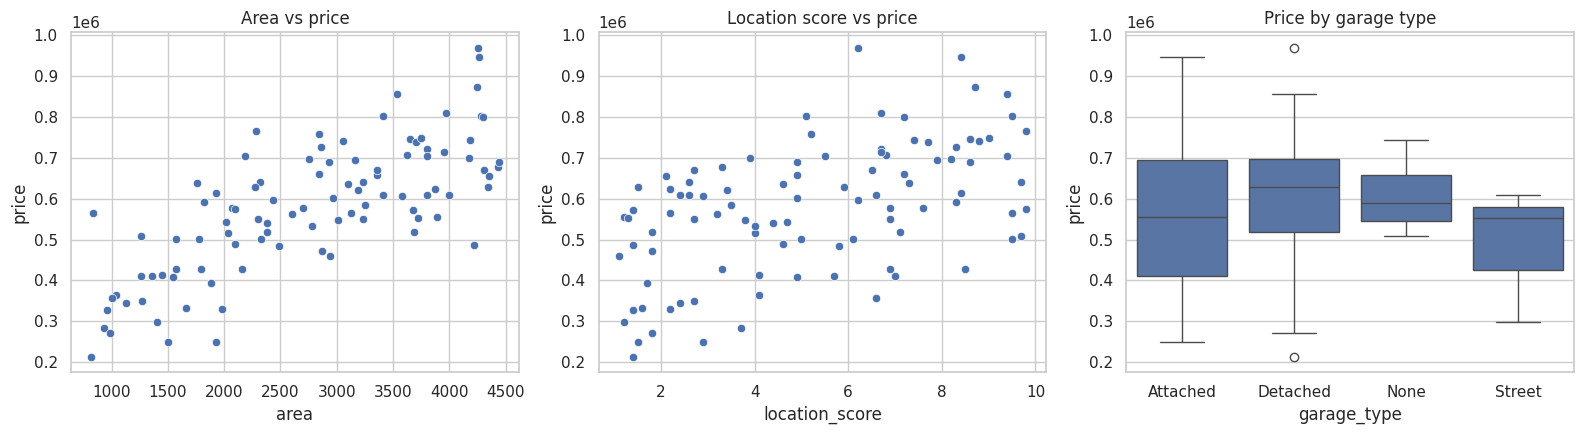

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.scatterplot(data=df, x="area", y="price", ax=ax[0])
sns.scatterplot(data=df, x="location_score", y="price", ax=ax[1])
sns.boxplot(data=df, x="garage_type", y="price", ax=ax[2])
ax[0].set_title("Area vs price")
ax[1].set_title("Location score vs price")
ax[2].set_title("Price by garage type")
plt.tight_layout()
plt.show()

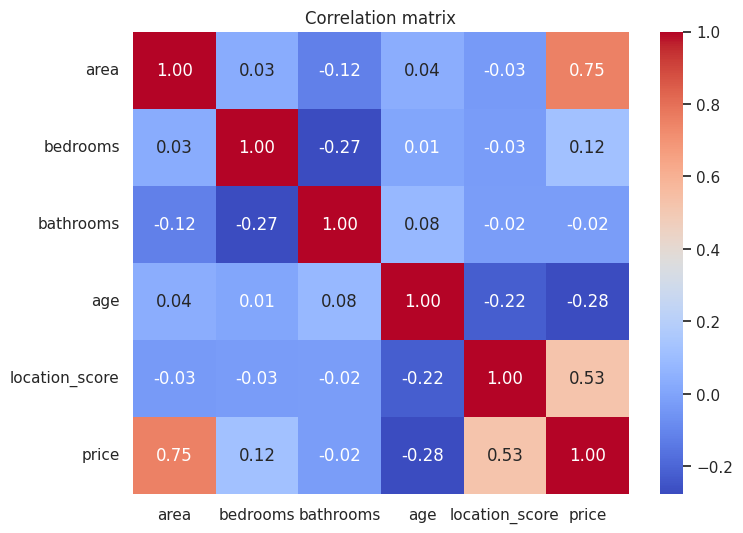

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()

**What we see:** `area` (r = 0.75) and `location_score` (r = 0.53) have the strongest positive link with price, `age` is negative (older = cheaper), and bedrooms and bathrooms matter little on their own. No pair of features is strongly correlated with each other, which is good for regression.

# 2. Build Model
### Prepare features
`garage_type` is converted to 0/1 columns (one column is dropped so the model is not confused).

In [ ]:
df = pd.get_dummies(df, columns=["garage_type"], drop_first=True, dtype=int)

X = df.drop("price", axis=1)
y = df["price"]
print(X.columns.tolist())

['area', 'bedrooms', 'bathrooms', 'age', 'location_score', 'condition', 'garage_type_Detached', 'garage_type_None', 'garage_type_Street']


### Split into training and testing data (80% / 20%)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (77, 9)  Test: (20, 9)


### Handle missing values
Missing `bathrooms` and `age` are filled with the **median of the training data** (the test data uses the same values, so no information leaks from the test set).

In [ ]:
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)
print("Missing left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Missing left: 0 0


### Train the linear regression model

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

coef = pd.Series(model.coef_, index=X.columns).sort_values(ascending=False)
print("Intercept:", round(model.intercept_, 2))
coef

Intercept: 5642.55


,0
location_score,"30,893.65"
bathrooms,"24,399.76"
condition,"17,556.58"
bedrooms,"15,388.67"
garage_type_Detached,"15,282.38"
area,117.28
age,"-1,160.90"
garage_type_Street,"-16,088.53"
garage_type_None,"-28,235.56"


# 3. Test Model
### Evaluation: MSE, RMSE and R²

In [ ]:
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)

results = pd.DataFrame({
    "Train": [mean_squared_error(y_train, pred_train), mean_squared_error(y_train, pred_train) ** 0.5,
              mean_absolute_error(y_train, pred_train), r2_score(y_train, pred_train)],
    "Test":  [mean_squared_error(y_test, pred_test), mean_squared_error(y_test, pred_test) ** 0.5,
              mean_absolute_error(y_test, pred_test), r2_score(y_test, pred_test)],
}, index=["MSE", "RMSE", "MAE", "R2"])
results

,Train,Test
MSE,"1,027,546,371.61","843,209,151.63"
RMSE,"32,055.36","29,038.06"
MAE,"25,031.10","24,195.28"
R2,0.95,0.98


In [ ]:
# 5-fold cross-validation (more reliable on a small dataset)
cv = cross_val_score(LinearRegression(), X.fillna(X.median()), y, cv=5, scoring="r2")
print("R2 for each fold:", cv.round(3))
print("Average R2:", round(cv.mean(), 3))
print("Average price:", round(y.mean()))

R2 for each fold: [0.963 0.959 0.919 0.937 0.957]
Average R2: 0.947
Average price: 576830


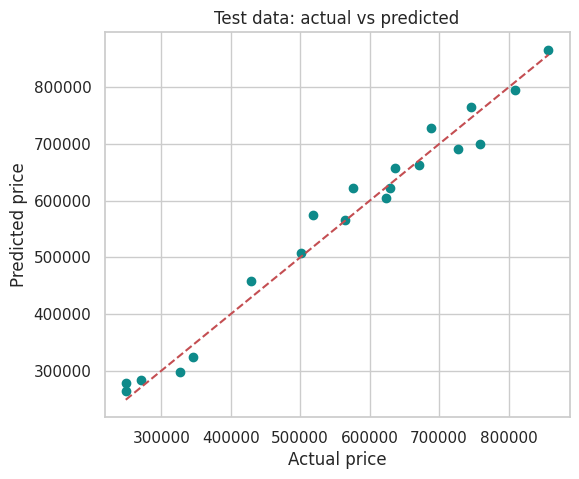

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, pred_test, color="#0E8A8A")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Test data: actual vs predicted")
plt.show()

### Interpretation of the metrics

| Metric | Train | Test | Meaning |
|---|---|---|---|
| **MSE** | about 1.03 billion | about 0.84 billion | Average squared error. It is in squared price units, so it is large and hard to read. |
| **RMSE** | about 32,055 | about 29,038 | Typical size of a prediction error. The average price is about 576,800, so the model is off by roughly **5%**. |
| **R²** | 0.95 | 0.98 | Share of the differences in price explained by the features. |

* **R² about 0.95** means the features explain about 95% of why house prices differ.
* Train and test scores are close, so the model is **not overfitting**. The test R² is slightly higher only because the test set has just 20 houses. The cross-validated R² of about **0.95** is the safest figure to quote.
* Predicting the average price for every house would give an RMSE of about 188,000, so the model is far better than guessing.
* **Coefficients:** each house gains about 30,900 for every extra point of `location_score`, 24,400 per bathroom, 17,600 per step of `condition`, 15,400 per bedroom and 117 per extra unit of `area`. Each extra year of `age` lowers the price by about 1,160. Having no garage lowers the price by about 28,200 compared with an attached garage.

### Check the linear regression assumptions
The checks use the **residuals** (actual price - predicted price) of the training data.

In [ ]:
fitted = model.predict(X_train)
resid = y_train - fitted
print("Average residual (should be about 0):", round(resid.mean(), 4))

Average residual (should be about 0): -0.0


#### 1. Linearity
Residuals should scatter randomly around 0 with no curve.

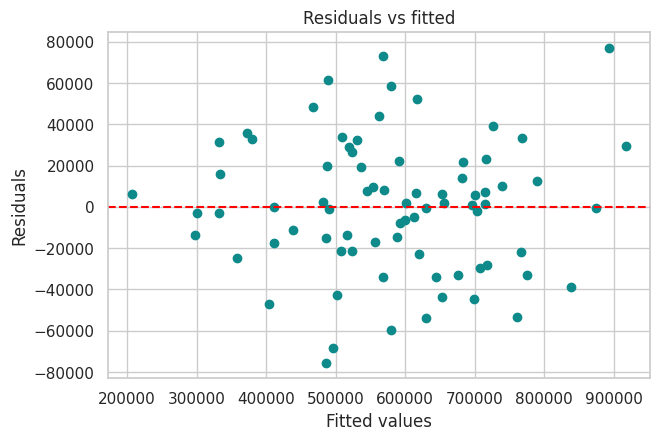

In [ ]:
plt.figure(figsize=(7, 4.5))
plt.scatter(fitted, resid, color="#0E8A8A")
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Fitted values")
plt.ylabel("Residuals")
plt.title("Residuals vs fitted")
plt.show()

**Result:** the points are spread randomly around zero with no curved pattern, so the relationship is **linear**.

#### 2. No multicollinearity
VIF (Variance Inflation Factor): below 5 is good, above 10 is a problem.

In [ ]:
vif = {}
for c in X_train.columns:
    others = X_train.drop(columns=c)
    r2 = LinearRegression().fit(others, X_train[c]).score(others, X_train[c])
    vif[c] = 1 / (1 - r2)
vif = pd.Series(vif).sort_values(ascending=False)
vif.round(2)

,0
garage_type_Detached,1.27
location_score,1.24
garage_type_None,1.22
age,1.17
garage_type_Street,1.16
bathrooms,1.13
bedrooms,1.13
area,1.11
condition,1.07


**Result:** the highest VIF is about 1.27, far below 5, so there is **no multicollinearity**. Each feature adds separate information.

#### 3. Normal errors
Residuals should follow a bell curve (histogram), lie on the line in the Q-Q plot, and the Shapiro-Wilk test should give p > 0.05.

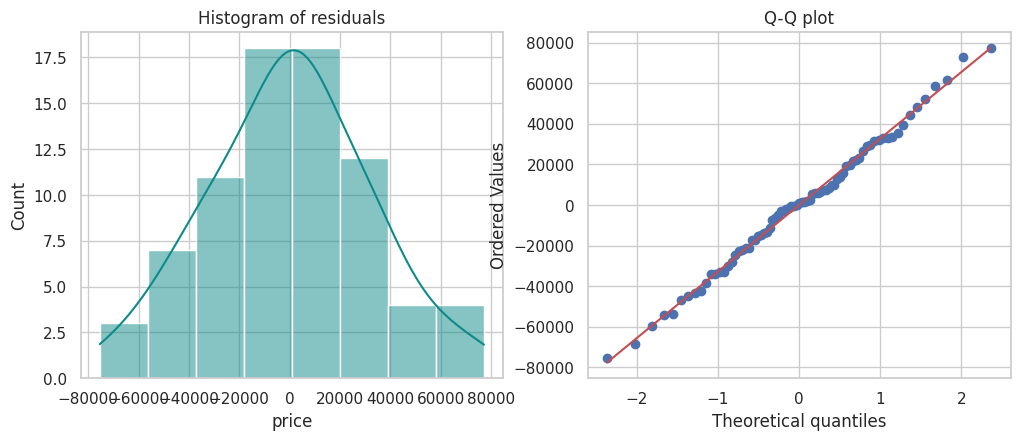

Shapiro-Wilk p-value: 0.9712


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(resid, kde=True, ax=ax[0], color="#0E8A8A")
ax[0].set_title("Histogram of residuals")
stats.probplot(resid, dist="norm", plot=ax[1])
ax[1].set_title("Q-Q plot")
plt.show()

stat, p_normal = stats.shapiro(resid)
print("Shapiro-Wilk p-value:", round(p_normal, 4))

**Result:** the histogram is bell-shaped, the points follow the line, and p = 0.97 (above 0.05), so the errors are **normally distributed**.

#### 4. Independent errors
Durbin-Watson is close to 2 when errors are independent (1.5 to 2.5 is acceptable).

Durbin-Watson: 2.046


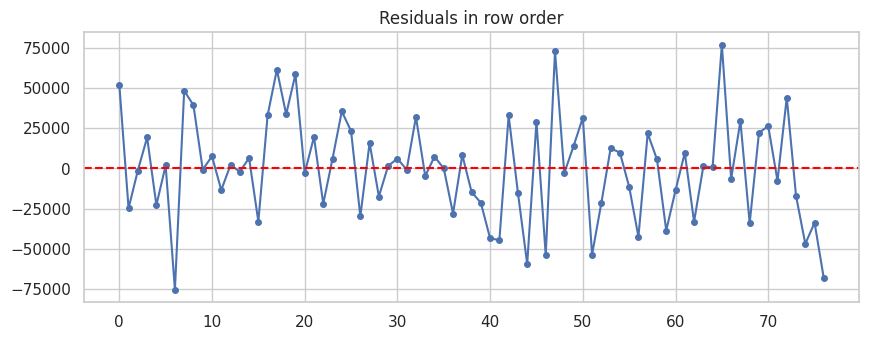

In [ ]:
dw = (np.diff(resid.sort_index()) ** 2).sum() / (resid ** 2).sum()
print("Durbin-Watson:", round(dw, 3))

plt.figure(figsize=(10, 3.5))
plt.plot(resid.sort_index().values, marker="o", markersize=4)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuals in row order")
plt.show()

**Result:** Durbin-Watson is about 2.05 and the residuals show no pattern, so the errors are **independent**.

#### 5. Homoscedasticity (constant variance)
Residuals should have the same spread everywhere (no funnel shape). Breusch-Pagan test: p > 0.05 means constant variance.

In [ ]:
r2_aux = LinearRegression().fit(X_train, resid ** 2).score(X_train, resid ** 2)
lm = len(resid) * r2_aux
p_bp = stats.chi2.sf(lm, X_train.shape[1])
print("Breusch-Pagan p-value:", round(p_bp, 4))

Breusch-Pagan p-value: 0.5918


**Result:** the residual plot above shows no funnel and p = 0.59 (above 0.05), so the variance is **constant**.

### Summary of assumptions

| Assumption | Test | Result | Pass? |
|---|---|---|---|
| Linearity | Residuals vs fitted plot | Random scatter around 0 | Yes |
| No multicollinearity | VIF | Highest about 1.27 (below 5) | Yes |
| Normal errors | Histogram, Q-Q plot, Shapiro-Wilk | p = 0.97 | Yes |
| Independent errors | Durbin-Watson | about 2.05 | Yes |
| Homoscedasticity | Residual plot, Breusch-Pagan | p = 0.59 | Yes |

# Conclusion
A linear regression model trained on 77 houses and tested on 20 predicts home prices with an R² of about 0.95 and a typical error of about 5% of the price. All five regression assumptions hold, so the model is valid and its coefficients can be trusted. **Location, number of bathrooms, condition and area** push the price up, **age** and **having no garage** push it down.

**Limitations:** the dataset is small (97 houses after cleaning), 3 unusual rows were removed, and the test set has only 20 houses, so results can change slightly with a different split.